# Secuencias mensuales por paciente - Proyecto HTA (SIS)

Este cuaderno prepara los datos para la red recurrente (`05_gru.ipynb`). Los cuadernos anteriores resumen los 24 meses de la ventana de observación en **una fila por paciente** (totales, promedios, máximos). Aquí se construye, para cada paciente, **una fila por mes**, de modo que el modelo pueda ver cómo evoluciona su historia en el tiempo.

```
dataset_consolidado.csv          →  1 fila por paciente   (419,226 × 36)
secuencias_X.npy  (este cuaderno) →  24 meses por paciente (419,226 × 24 × F)
```

| Decisión | Elección |
|---|---|
| Cohorte, `y` y partición | **Las mismas** de `dataset_consolidado.csv` y de `02_modelos` / `03_random_forest` (80/20 estratificado, semilla 42; validación = 20% del train). Así los resultados son comparables |
| Unidad de tiempo | Mes calendario: enero 2022 = mes 0 … diciembre 2023 = mes 23. Longitud fija de 24 pasos |
| Variables por mes | Uso del sistema, presión arterial, diagnósticos del mes y consumos (sección 4) |
| Meses sin atenciones | Todas las variables en 0 y el indicador `sin_atencion` = 1: no ir al establecimiento también es información |
| Presión no medida | 0 después de estandarizar + indicador `pa_medida` = 0. No se imputa: la red aprende a ignorarla |
| Escalado | `log1p` en los conteos y estandarización con media y desviación **solo de train** |
| Salidas | `secuencias_X.npy`, `secuencias_estaticas.npy`, `secuencias_meta.csv`, `secuencias_variables.json` en `data/processed/` |

La limpieza de FUAS (rangos de presión, días de hospitalización) es la misma del preprocesamiento.

## 1. Inicializar

In [1]:
import gc
import json
from pathlib import Path
import numpy as np
import pandas as pd
from pandas.api.types import union_categoricals
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

AZUL, NARANJA, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
GRIS, TEXTO, TEXTO_2 = '#a3a29b', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ad',
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlecolor': TEXTO, 'axes.labelcolor': TEXTO_2,
    'xtick.color': TEXTO_2, 'ytick.color': TEXTO_2,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'legend.frameon': False,
})

In [2]:
# --- Parámetros del trabajo ---
# Carpeta de los CSV/ZIP del SIS. None = buscarla automáticamente (carpeta actual, data/raw/ o carpetas superiores)
RUTA_MANUAL = None
SEED = 42
FIN_OBS = 20231231        # solo atenciones de la ventana de observación (2022-2023)
INI_OBS = 20220101
N_MESES = 24
CHUNK = 2_000_000         # filas por bloque al leer los CSV

def buscar_carpeta(nombre_archivo, subcarpeta):
    # Primera carpeta (actual, <p>/<subcarpeta> o superiores) que contiene el archivo
    for p in [Path.cwd(), *Path.cwd().parents]:
        for d in (p, p / subcarpeta):
            for ext in ('.csv', '.zip', ''):
                f = d / f'{nombre_archivo}{ext}'
                if f.exists() and not (ext == '.zip' and f.stat().st_size < 10_000):   # descarta punteros de Git LFS
                    return d
    raise FileNotFoundError(f"No se encontró {nombre_archivo} desde {Path.cwd()}")

RUTA_RAW = Path(RUTA_MANUAL) if RUTA_MANUAL else buscar_carpeta('1. HTA_FUAS', Path('data') / 'raw')
RUTA_OUT = buscar_carpeta('dataset_consolidado.csv', Path('data') / 'processed')

def ruta(nombre):
    csv = RUTA_RAW / f'{nombre}.csv'
    return csv if csv.exists() else RUTA_RAW / f'{nombre}.zip'

print("Datos crudos:", RUTA_RAW, "| Dataset consolidado y salidas:", RUTA_OUT)

Datos crudos: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA | Dataset consolidado y salidas: C:\Users\ROG STRIX\Desktop\IA\ProyectoIA\data\processed


## 2. Cohorte, `y` y partición
Se parte de `dataset_consolidado.csv`: define **qué pacientes** entran (la cohorte), su `y` y las variables estáticas. La partición se reconstruye con **las mismas llamadas** a `train_test_split` que en `02_modelos` y `03_random_forest` (mismo orden de filas, misma semilla, mismo estratificado), así que el test es exactamente el mismo conjunto de pacientes.

In [3]:
base = pd.read_csv(RUTA_OUT / 'dataset_consolidado.csv', index_col='paciente')
N = len(base)
y = base['y']

X_tmp = base.drop(columns='y')
X_train, X_test, y_train, y_test = train_test_split(X_tmp, y, test_size=0.2, random_state=SEED, stratify=y)
idx_tr, idx_val = train_test_split(X_train.index, test_size=0.2, random_state=SEED, stratify=y_train)
del X_tmp, X_train, X_test

meta = pd.DataFrame({'paciente': base.index, 'fila': np.arange(N), 'y': y.values})
meta['conjunto'] = 'train'
meta.loc[meta['paciente'].isin(idx_val), 'conjunto'] = 'val'
meta.loc[meta['paciente'].isin(y_test.index), 'conjunto'] = 'test'
fila_de = pd.Series(meta['fila'].values, index=meta['paciente'])   # código anonimizado -> fila del tensor
es_train = (meta['conjunto'] == 'train').values

meta.groupby('conjunto')['y'].agg(Pacientes='size', Tasa_y='mean').round(4)

,Pacientes,Tasa_y
conjunto,,
test,83846,0.056
train,268304,0.056
val,67076,0.056


## 3. Atenciones (FUAS) de la cohorte en 2022-2023
Se leen por bloques solo las atenciones de los pacientes de la cohorte dentro de la ventana de observación. A cada atención se le asigna su **fila** (paciente) y su **mes** (0-23). La limpieza de presión arterial es la misma del preprocesamiento corregido (comparación en `float64` con numpy).

In [4]:
COLS = ['CODIGO_ANONIMIZADO', 'ID_REGISTRO_REL', 'FECHA_ATENCION', 'NIVEL_EESS', 'SERVICIO_PRESTACIONAL',
        'DIAS_HOSP', 'PRES_ART_SISTOLICA', 'PRES_ART_DIASTOLICA', 'ES_CAPITA']
TIPOS = {'CODIGO_ANONIMIZADO': str, 'ID_REGISTRO_REL': 'int64', 'FECHA_ATENCION': 'int32', 'NIVEL_EESS': 'int8',
         'SERVICIO_PRESTACIONAL': str, 'DIAS_HOSP': 'float32', 'PRES_ART_SISTOLICA': 'float32',
         'PRES_ART_DIASTOLICA': 'float32', 'ES_CAPITA': str}
TIPOS['FECHA_ATENCION'] = 'int64'
cohorte = set(base.index)

partes = []
conteo_directo = pd.Series(0, index=pd.period_range('2022-01', periods=N_MESES, freq='M').strftime('%Y%m'), dtype='int64')
for b in pd.read_csv(ruta('1. HTA_FUAS'), usecols=COLS, dtype=TIPOS, chunksize=CHUNK):
    b = b[b['FECHA_ATENCION'].between(INI_OBS, FIN_OBS) & b['CODIGO_ANONIMIZADO'].isin(cohorte)]
    if b.empty:
        continue
    # Mes 0-23 a partir del texto 'AAAAMMDD' (año y mes leídos por separado)
    fecha_txt = b['FECHA_ATENCION'].astype(str)
    anio = fecha_txt.str[:4].astype('int64').to_numpy()
    mes_cal = fecha_txt.str[4:6].astype('int64').to_numpy()
    conteo_directo = conteo_directo.add(fecha_txt.str[:6].value_counts(), fill_value=0).astype('int64')
    t = pd.DataFrame({
        'fila': fila_de.loc[b['CODIGO_ANONIMIZADO']].values.astype('int32'),
        'mes': ((anio - 2022) * 12 + mes_cal - 1).astype('int16'),
        'ID_REGISTRO_REL': b['ID_REGISTRO_REL'].values,
        'nivel': b['NIVEL_EESS'].values,
        'emergencia': b['SERVICIO_PRESTACIONAL'].str.upper().str.contains('EMERGENCIA').astype('int8').values,
        'dias_hosp': b['DIAS_HOSP'].fillna(0).clip(upper=365).values,
        'pas': b['PRES_ART_SISTOLICA'].to_numpy(dtype='float64', na_value=np.nan),
        'pad': b['PRES_ART_DIASTOLICA'].to_numpy(dtype='float64', na_value=np.nan),
        'capita': (b['ES_CAPITA'] == 'S').astype('int8').values,
    })
    partes.append(t)
fuas = pd.concat(partes, ignore_index=True)
del partes
gc.collect()

# Limpieza de presión arterial (mismos rangos que el preprocesamiento)
medida = ~np.isnan(fuas['pas'].values) & ~np.isnan(fuas['pad'].values)
valida = medida & fuas['pas'].between(60, 260).values & fuas['pad'].between(30, 150).values & (fuas['pas'] > fuas['pad']).values
print(f"Atenciones de la cohorte en 2022-2023: {len(fuas):,} | presiones imposibles anuladas: {(medida & ~valida).sum():,}")
assert (medida & ~valida).sum() / max(medida.sum(), 1) < 0.05, "Se están anulando demasiadas presiones"
fuas.loc[~valida, ['pas', 'pad']] = np.nan
fuas['pa_medida'] = valida.astype('int8')
fuas['pa_alta'] = (valida & ((fuas['pas'] >= 140) | (fuas['pad'] >= 90)).values).astype('int8')
fuas['hospitalizado'] = (fuas['dias_hosp'] > 0).astype('int8')
assert fuas['mes'].between(0, N_MESES - 1).all()

# Control 1: las atenciones asignadas a cada mes deben coincidir con el conteo directo por año-mes de la fecha
por_mes = pd.Series(np.bincount(fuas['mes'].values, minlength=N_MESES), index=conteo_directo.index)
control_meses = pd.DataFrame({'Atenciones (conteo directo)': conteo_directo, 'Atenciones (mes asignado)': por_mes})
control_meses['Diferencia'] = control_meses['Atenciones (mes asignado)'] - control_meses['Atenciones (conteo directo)']
display(control_meses.T)
assert (control_meses['Diferencia'] == 0).all(), "El mes asignado no coincide con la fecha: revisar la columna FECHA_ATENCION"
# Control 2: ningún mes debería tener mucho más que el resto (en el EDA, enero 2022 tuvo ~450 mil atenciones de TODOS los pacientes)
razon = por_mes.max() / por_mes.median()
print(f"Mes con más atenciones / mediana de los meses = {razon:.2f}")
if razon > 2:
    print("ATENCIÓN: hay un mes con más del doble de atenciones que la mediana. Revisar antes de modelar.")

Atenciones de la cohorte en 2022-2023: 8,546,298 | presiones imposibles anuladas: 740


,202201,202202,202203,202204,202205,202206,202207,202208,202209,202210,...,202303,202304,202305,202306,202307,202308,202309,202310,202311,202312
Atenciones (conteo directo),236033,259659,314095,307024,330677,299588,304876,320226,335798,329901,...,418553,384697,415472,396315,402933,429826,430952,428035,430750,374252
Atenciones (mes asignado),236033,259659,314095,307024,330677,299588,304876,320226,335798,329901,...,418553,384697,415472,396315,402933,429826,430952,428035,430750,374252
Diferencia,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Mes con más atenciones / mediana de los meses = 1.19


**Resultado.** Las 8,546,298 atenciones de la cohorte en 2022-2023 quedaron asignadas a su mes correcto: el conteo directo por año-mes de la fecha y el mes asignado coinciden en los 24 meses, sin una sola diferencia. El volumen crece de forma sostenida, de 236,033 atenciones en enero de 2022 a ≈430,000 por mes en el segundo semestre de 2023, y ningún mes se aparta del resto (el mes más alto tiene 1.19 veces la mediana).

> **Nota de calidad.** Este control se agregó porque una versión anterior del cuaderno calculaba el mes con operaciones aritméticas sobre la fecha y, en este entorno, asignó ≈1 millón de atenciones a enero de 2022. Los totales por paciente seguían cuadrando, así que el error solo era visible comparando mes a mes. Ahora el mes se lee como texto (`AAAAMM`) y la celda se detiene si hay cualquier discrepancia.

## 4. Variables por paciente y mes

| Grupo | Variable | Cálculo en el mes |
|---|---|---|
| Uso | `n_atenciones`, `n_emergencias`, `n_hospitalizaciones`, `dias_hosp` | Conteos y suma de días |
| Uso | `nivel_eess_max`, `prop_capita` | Nivel más alto de establecimiento; proporción de atenciones por cápita |
| Presión | `pa_medida`, `pas_media`, `pad_media`, `pa_alta` | ¿Se midió?; medias del mes; ¿alguna medición ≥ 140/90? |
| Diagnósticos | `diabetes`, `dislipidemia`, `obesidad`, `fib_auricular`, `cardiopatia`, `hta_cardiaca`, `n_diagnosticos` | ¿Se registró en el mes? (definitivo o repetido); n.º de diagnósticos |
| Consumos | `n_medicamentos`, `n_procedimientos`, `n_insumos` | Registros del mes |
| Actividad | `sin_atencion` | 1 si el paciente no tuvo ninguna atención ese mes |

### 4.1 Desde FUAS

In [5]:
VARIABLES = ['n_atenciones', 'n_emergencias', 'n_hospitalizaciones', 'dias_hosp', 'nivel_eess_max', 'prop_capita',
             'pa_medida', 'pas_media', 'pad_media', 'pa_alta',
             'diabetes', 'dislipidemia', 'obesidad', 'fib_auricular', 'cardiopatia', 'hta_cardiaca', 'n_diagnosticos',
             'n_medicamentos', 'n_procedimientos', 'n_insumos', 'sin_atencion']
F = len(VARIABLES)
col = {v: i for i, v in enumerate(VARIABLES)}
X = np.zeros((N, N_MESES, F), dtype='float32')
print(f"Tensor: {N:,} pacientes × {N_MESES} meses × {F} variables = {X.nbytes / 1e9:.2f} GB")

g = fuas.groupby(['fila', 'mes'])
mensual = g.agg(n_atenciones=('ID_REGISTRO_REL', 'size'), n_emergencias=('emergencia', 'sum'),
                n_hospitalizaciones=('hospitalizado', 'sum'), dias_hosp=('dias_hosp', 'sum'),
                nivel_eess_max=('nivel', 'max'), prop_capita=('capita', 'mean'),
                pa_medida=('pa_medida', 'max'), pas_media=('pas', 'mean'), pad_media=('pad', 'mean'),
                pa_alta=('pa_alta', 'max')).reset_index()
f_idx, m_idx = mensual['fila'].values, mensual['mes'].values
for v in ['n_atenciones', 'n_emergencias', 'n_hospitalizaciones', 'dias_hosp', 'nivel_eess_max', 'prop_capita',
          'pa_medida', 'pas_media', 'pad_media', 'pa_alta']:
    X[f_idx, m_idx, col[v]] = np.nan_to_num(mensual[v].values.astype('float32'), nan=0.0)   # PA no medida -> 0 por ahora
X[:, :, col['sin_atencion']] = (X[:, :, col['n_atenciones']] == 0)
# Control 3: el tensor debe tener, en cada mes, exactamente las atenciones asignadas a ese mes
assert np.array_equal(X[:, :, col['n_atenciones']].sum(axis=0).astype('int64'), por_mes.values), "El tensor no reproduce las atenciones por mes"
print("Control del tensor por mes: OK")

# Tabla ID de atención -> (fila, mes), ordenada, para ubicar diagnósticos y consumos sin hacer merges gigantes
orden = np.argsort(fuas['ID_REGISTRO_REL'].values, kind='stable')
ids_ord = fuas['ID_REGISTRO_REL'].values[orden]
fila_ord = fuas['fila'].values[orden]
mes_ord = fuas['mes'].values[orden]
del mensual, g, orden
gc.collect()

def ubicar(ids):
    # Devuelve (fila, mes, encontrado) para cada ID de atención; 'encontrado' = la atención es de la cohorte en 2022-2023
    pos = np.searchsorted(ids_ord, ids)
    pos = np.clip(pos, 0, len(ids_ord) - 1)
    encontrado = ids_ord[pos] == ids
    return fila_ord[pos], mes_ord[pos], encontrado

Tensor: 419,226 pacientes × 24 meses × 21 variables = 0.85 GB
Control del tensor por mes: OK


### 4.2 Desde Diagnósticos (solo `DEFINITIVO` y `REPETIDO`)

In [6]:
GRUPOS = {'diabetes': ('E10', 'E11', 'E12', 'E13', 'E14'), 'dislipidemia': ('E78',), 'obesidad': ('E66',),
          'fib_auricular': ('I48',), 'cardiopatia': ('I20', 'I24', 'I25'), 'hta_cardiaca': ('I119',)}
for b in pd.read_csv(ruta('2. HTA_Diagnosticos'), usecols=['ID_REGISTRO_REL', 'CODDIA', 'TIPO_DIAGNOSTICO'],
                     dtype={'ID_REGISTRO_REL': 'int64', 'CODDIA': str, 'TIPO_DIAGNOSTICO': str}, chunksize=CHUNK):
    b = b[b['TIPO_DIAGNOSTICO'].str.strip().isin(['DEFINITIVO', 'REPETIDO'])].drop_duplicates()
    fila, mes, ok = ubicar(b['ID_REGISTRO_REL'].values)
    if not ok.any():
        continue
    fila, mes = fila[ok], mes[ok]
    cod = b['CODDIA'].values[ok].astype(str)
    cod = pd.Series(cod).str.strip().str.upper()
    np.add.at(X, (fila, mes, np.full(len(fila), col['n_diagnosticos'])), 1)
    for nombre, prefijos in GRUPOS.items():
        m = cod.str.startswith(prefijos).values
        X[fila[m], mes[m], col[nombre]] = 1
print("Diagnósticos listos. Pacientes-mes con diabetes registrada:", int(X[:, :, col['diabetes']].sum()))

Diagnósticos listos. Pacientes-mes con diabetes registrada: 650116


### 4.3 Desde Medicamentos, Procedimientos e Insumos
Se cuentan los registros de cada paciente en cada mes. *Nota:* los duplicados exactos se eliminan dentro de cada bloque de lectura; en el preprocesamiento eran muy pocos (≈3,800 en procedimientos, 0 en las otras tablas), así que el efecto es despreciable.

In [7]:
for archivo, variable in [('3. HTA_Medicamentos', 'n_medicamentos'), ('4. HTA_Procedimientos', 'n_procedimientos'),
                          ('5. HTA_Insumos', 'n_insumos')]:
    total = 0
    for b in pd.read_csv(ruta(archivo), chunksize=CHUNK, dtype=str):   # todo como texto: evita el DtypeWarning de columnas mixtas
        b = b.drop_duplicates()
        fila, mes, ok = ubicar(b['ID_REGISTRO_REL'].astype('int64').values)
        np.add.at(X, (fila[ok], mes[ok], np.full(ok.sum(), col[variable])), 1)
        total += ok.sum()
    print(f"{variable}: {total:,} registros asignados")
del fuas
_ = gc.collect()

n_medicamentos: 12,859,997 registros asignados
n_procedimientos: 15,139,765 registros asignados
n_insumos: 4,472,274 registros asignados


## 5. Verificación contra el dataset consolidado
Si las secuencias están bien construidas, al **sumar los 24 meses** de cada paciente deben salir los mismos totales que `dataset_consolidado.csv`. Es la mejor prueba de que no se perdieron ni duplicaron atenciones.

In [8]:
controles = {'n_atenciones': 'n_atenciones', 'n_emergencias': 'n_emergencias', 'n_hospitalizaciones': 'n_hospitalizaciones'}
filas = []
for v_seq, v_base in controles.items():
    suma = X[:, :, col[v_seq]].sum(axis=1)
    iguales = np.isclose(suma, base[v_base].values)
    filas.append({'Variable': v_base, 'Pacientes que coinciden (%)': iguales.mean() * 100,
                  'Total secuencias': suma.sum(), 'Total consolidado': base[v_base].sum()})
verif = pd.DataFrame(filas).set_index('Variable')
display(verif)
assert verif['Pacientes que coinciden (%)'].min() > 99.9, "Las secuencias no coinciden con el dataset consolidado"

# Las variables de diagnóstico: un paciente con diabetes en el consolidado debe tenerla en algún mes
for v in ['diabetes', 'dislipidemia', 'obesidad', 'fib_auricular', 'cardiopatia', 'hta_cardiaca']:
    if v in base.columns:
        alguna = X[:, :, col[v]].max(axis=1)
        print(f"{v}: coincide en {(alguna == base[v].values).mean():.2%} de los pacientes")

,Pacientes que coinciden (%),Total secuencias,Total consolidado
Variable,,,
n_atenciones,100.0,8546298.0,8546298
n_emergencias,100.0,438245.0,438245
n_hospitalizaciones,100.0,69263.0,69263


diabetes: coincide en 100.00% de los pacientes
dislipidemia: coincide en 100.00% de los pacientes
obesidad: coincide en 100.00% de los pacientes
fib_auricular: coincide en 100.00% de los pacientes
cardiopatia: coincide en 100.00% de los pacientes
hta_cardiaca: coincide en 100.00% de los pacientes


**Resultado.** La reconstrucción es exacta. Sumando los 24 meses de cada paciente se obtienen las mismas 8,546,298 atenciones, 438,245 emergencias y 69,263 hospitalizaciones que en `dataset_consolidado.csv`, con coincidencia en el **100% de los pacientes**. Las seis comorbilidades también coinciden en el 100%: todo paciente marcado con diabetes, dislipidemia, obesidad, fibrilación auricular, cardiopatía isquémica o cardiopatía hipertensiva en el consolidado la tiene registrada en al menos un mes de la secuencia.

Junto con el control mensual de la sección 3 y el control del tensor de la sección 4.1, esto garantiza que el tensor contiene **la misma información** que los modelos tabulares, solo que **ordenada en el tiempo**. Cualquier diferencia de desempeño entre la red recurrente y los modelos de `02` y `03` se debe a cómo se presenta la información, no a que una tenga datos que la otra no tiene.

## 6. ¿Hay señal en el tiempo?
Antes de entrenar la red conviene ver si la historia mensual **se ve distinta** entre los pacientes que se complican en 2024 y los que no. Si las curvas de ambos grupos se separan más en los últimos meses, hay una señal temporal que un modelo agregado no captura.

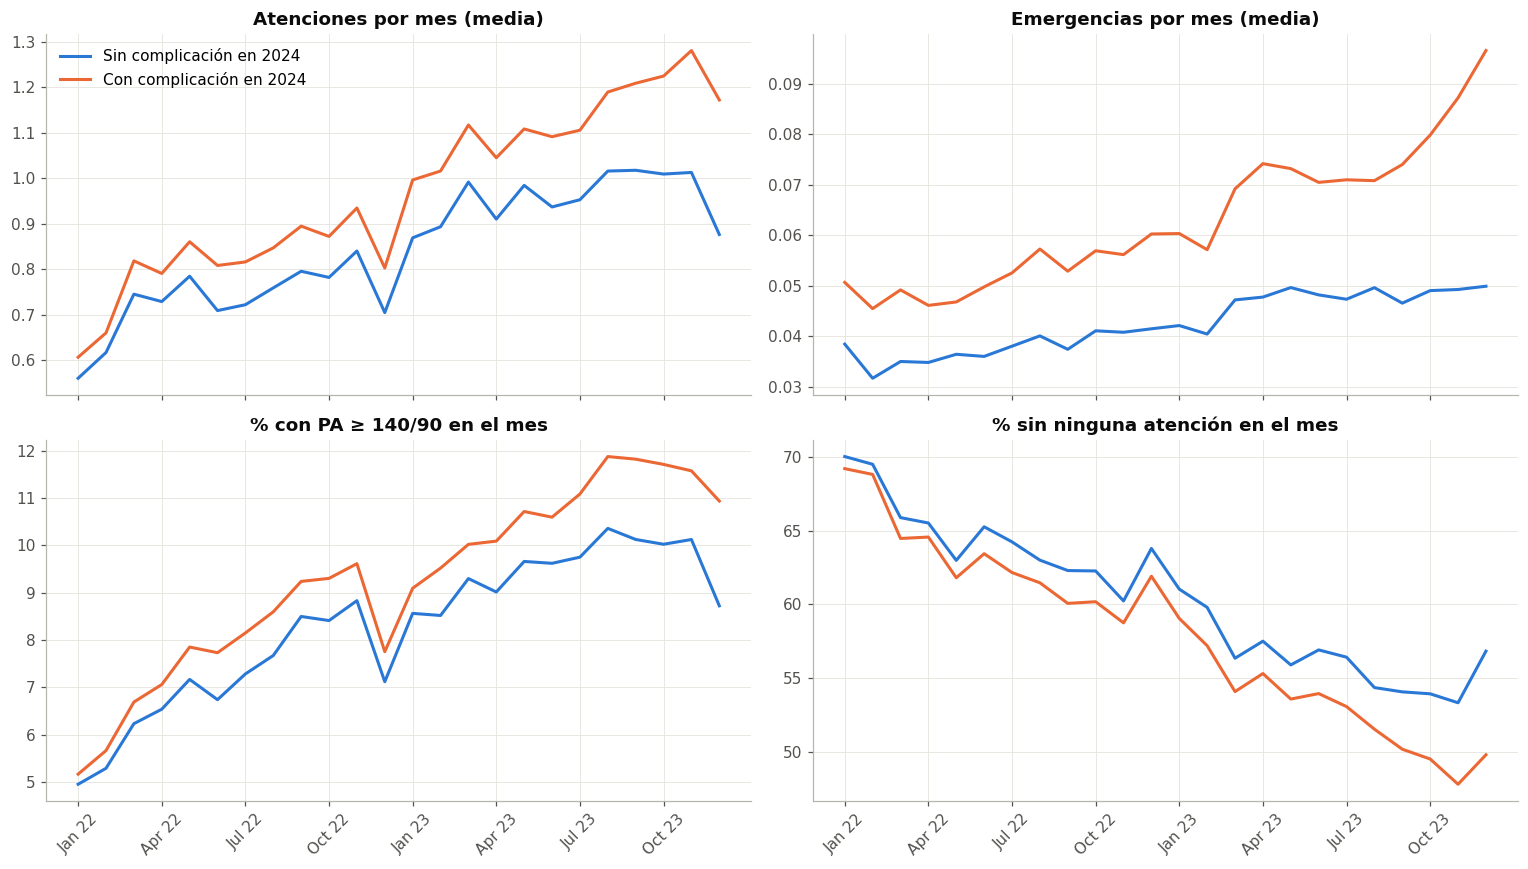

,Razón y=1 / y=0 (ene-jun 2022),Razón y=1 / y=0 (jul-dic 2023)
Variable,,
n_atenciones,1.10,1.22
n_emergencias,1.36,1.64
pa_alta,1.09,1.17
sin_atencion,0.98,0.92


In [9]:
yv = meta['y'].values == 1
meses = pd.period_range('2022-01', periods=N_MESES, freq='M').strftime('%b %y')
paneles = [('n_atenciones', 'Atenciones por mes (media)'), ('n_emergencias', 'Emergencias por mes (media)'),
           ('pa_alta', '% con PA ≥ 140/90 en el mes'), ('sin_atencion', '% sin ninguna atención en el mes')]
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, (v, titulo) in zip(axes.flat, paneles):
    escala = 100 if v in ('pa_alta', 'sin_atencion') else 1
    ax.plot(range(N_MESES), X[~yv, :, col[v]].mean(axis=0) * escala, color=AZUL, linewidth=2, label='Sin complicación en 2024')
    ax.plot(range(N_MESES), X[yv, :, col[v]].mean(axis=0) * escala, color=NARANJA, linewidth=2, label='Con complicación en 2024')
    ax.set_title(titulo)
    ax.set_xticks(range(0, N_MESES, 3), meses[::3], rotation=45)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

# Diferencia relativa entre grupos: primer semestre de 2022 vs último semestre de 2023
filas = []
for v, _ in paneles:
    a0, a1 = X[~yv, :6, col[v]].mean(), X[yv, :6, col[v]].mean()
    b0, b1 = X[~yv, -6:, col[v]].mean(), X[yv, -6:, col[v]].mean()
    filas.append({'Variable': v, 'Razón y=1 / y=0 (ene-jun 2022)': a1 / max(a0, 1e-9), 'Razón y=1 / y=0 (jul-dic 2023)': b1 / max(b0, 1e-9)})
pd.DataFrame(filas).set_index('Variable').round(2)

**Interpretación.** Hay una señal temporal clara, y es la principal justificación del enfoque secuencial.

1. **La brecha entre grupos se abre con el tiempo.** Los pacientes que se complicarán en 2024 siempre usan más el sistema, pero la diferencia crece entre el inicio y el final de la ventana:

| Variable | Razón y=1 / y=0, ene-jun 2022 | Razón y=1 / y=0, jul-dic 2023 |
|---|---|---|
| Emergencias por mes | 1.36 | **1.64** |
| Atenciones por mes | 1.10 | **1.22** |
| Meses con PA ≥ 140/90 | 1.09 | **1.17** |
| Meses sin ninguna atención | 0.98 | **0.92** |

2. **Las emergencias son la señal más fuerte.** En el grupo que se complicará, las emergencias por paciente casi se duplican a lo largo de la ventana (de ≈0.05 a ≈0.097 por mes) y se aceleran en los últimos cuatro meses de 2023. En el grupo que no se complica, se mantienen casi planas (≈0.04-0.05). Es el patrón de un **deterioro progresivo** previo al evento: el paciente empieza a descompensarse y consulta de urgencia antes de que se registre la complicación.
3. **La presión no controlada también diverge.** El porcentaje de pacientes con al menos una medición ≥ 140/90 sube en ambos grupos (por el aumento general de atenciones), pero más en el que se complica: 11.9% frente a 10.4% en agosto de 2023.
4. **Un total de dos años diluye esta señal.** Para un modelo agregado, un paciente con 6 emergencias repartidas en 2022 y otro con 6 emergencias concentradas en el último trimestre de 2023 son idénticos. Clínicamente, el segundo está en un riesgo mucho mayor. Una red recurrente puede distinguirlos.

Dos observaciones de contexto: ambas curvas suben a lo largo del período porque el volumen total de atenciones del SIS creció (ver `01_eda.ipynb`), y en diciembre de 2022 y diciembre de 2023 hay una caída estacional de atenciones en ambos grupos, típica del cierre de año. Ninguna de las dos afecta la comparación entre grupos, porque las sufren por igual.

## 7. Escalado (solo con train)
- **Conteos** (`n_*`, `dias_hosp`): `log1p` y luego estandarización.
- **Presión** (`pas_media`, `pad_media`): estandarización usando solo los meses en que **se midió**; los meses sin medición quedan en 0 (= la media) y `pa_medida` = 0 le avisa a la red.
- **Binarias y proporciones** (`pa_medida`, `pa_alta`, comorbilidades, `prop_capita`, `sin_atencion`): sin cambios.
- `nivel_eess_max` (0-3): se divide por 3.

Las medias y desviaciones se calculan **solo con los pacientes de train**, como el `StandardScaler` de los otros cuadernos, y se guardan en `secuencias_variables.json`.

In [10]:
# Control: esta celda transforma X en el lugar; ejecutarla dos veces lo dejaría mal escalado
assert not globals().get('ESCALADO', False), "La celda de escalado ya se ejecutó: usa Restart & Run All en vez de repetirla"
CONTEOS = ['n_atenciones', 'n_emergencias', 'n_hospitalizaciones', 'dias_hosp', 'n_diagnosticos',
           'n_medicamentos', 'n_procedimientos', 'n_insumos']
PRESION = ['pas_media', 'pad_media']
estadisticas = {}

for v in CONTEOS:
    j = col[v]
    X[:, :, j] = np.log1p(X[:, :, j])
    mu, sd = float(X[es_train, :, j].mean()), float(X[es_train, :, j].std() + 1e-6)
    X[:, :, j] = (X[:, :, j] - mu) / sd
    estadisticas[v] = {'transformacion': 'log1p + estandarizacion', 'media': mu, 'desv': sd}

medida_mask = X[:, :, col['pa_medida']] == 1
for v in PRESION:
    j = col[v]
    valores_train = X[es_train, :, j][medida_mask[es_train]]
    mu, sd = float(valores_train.mean()), float(valores_train.std() + 1e-6)
    X[:, :, j] = np.where(medida_mask, (X[:, :, j] - mu) / sd, 0.0)
    estadisticas[v] = {'transformacion': 'estandarizacion (solo meses medidos); no medido = 0', 'media': mu, 'desv': sd}

X[:, :, col['nivel_eess_max']] /= 3.0
estadisticas['nivel_eess_max'] = {'transformacion': 'dividido por 3'}
ESCALADO = True

Xt = X[es_train].reshape(-1, F)          # copia temporal de train para el resumen
resumen = pd.DataFrame({'media (train)': Xt.mean(axis=0), 'desv (train)': Xt.std(axis=0),
                        'mín': X.reshape(-1, F).min(axis=0), 'máx': X.reshape(-1, F).max(axis=0)}, index=VARIABLES)
del Xt
gc.collect()
resumen.round(3)

,media (train),desv (train),mín,máx
n_atenciones,-0.003,0.991,-0.721,6.497000
n_emergencias,-0.001,0.986,-0.186,26.318001
n_hospitalizaciones,-0.000,0.997,-0.081,33.536999
dias_hosp,0.000,0.997,-0.074,36.153999
nivel_eess_max,0.202,0.298,0.000,1.000000
prop_capita,0.238,0.405,0.000,1.000000
pa_medida,0.282,0.454,0.000,1.000000
pas_media,0.000,0.529,-3.169,7.002000
pad_media,-0.000,0.529,-2.956,7.331000
pa_alta,0.083,0.268,0.000,1.000000


### 7.1 Variables estáticas
Las características que no cambian mes a mes entran a la red por separado (se concatenan al estado final de la GRU): edad, sexo, altitud del establecimiento y si se atiende en Lima. Se estandarizan con train; la edad faltante (3 pacientes) se imputa con la mediana de train.

In [11]:
ESTATICAS = ['edad', 'masculino', 'altitud_msnm', 'es_lima_frecuente']
E = base[ESTATICAS].astype('float32').copy()
mediana_edad = float(E.loc[es_train, 'edad'].median())
E['edad'] = E['edad'].fillna(mediana_edad)
for v in ['edad', 'altitud_msnm']:
    mu, sd = float(E.loc[es_train, v].mean()), float(E.loc[es_train, v].std() + 1e-6)
    E[v] = (E[v] - mu) / sd
    estadisticas[v] = {'transformacion': 'estandarizacion', 'media': mu, 'desv': sd}
estadisticas['edad']['mediana_imputacion'] = mediana_edad
E = E.values.astype('float32')
E.shape

(419226, 4)

## 8. Guardar

In [12]:
for nombre_var in ['X', 'E', 'meta', 'estadisticas']:
    assert nombre_var in globals(), f"Falta '{nombre_var}': ejecuta todas las celdas anteriores (Restart & Run All)"
assert globals().get('ESCALADO', False), "X no está escalado: ejecuta la sección 7"
np.save(RUTA_OUT / 'secuencias_X.npy', X)
np.save(RUTA_OUT / 'secuencias_estaticas.npy', E)
meta.to_csv(RUTA_OUT / 'secuencias_meta.csv', index=False)
with open(RUTA_OUT / 'secuencias_variables.json', 'w', encoding='utf-8') as f:
    json.dump({'variables_mensuales': VARIABLES, 'variables_estaticas': ESTATICAS, 'n_meses': N_MESES,
               'mes_0': '2022-01', 'estadisticas': estadisticas}, f, ensure_ascii=False, indent=1)
for nombre in ['secuencias_X.npy', 'secuencias_estaticas.npy', 'secuencias_meta.csv', 'secuencias_variables.json']:
    print(f"{nombre}: {(RUTA_OUT / nombre).stat().st_size / 1e6:,.1f} MB")

secuencias_X.npy: 845.2 MB
secuencias_estaticas.npy: 6.7 MB
secuencias_meta.csv: 33.6 MB
secuencias_variables.json: 0.0 MB


## Resumen
1. **Tensor de 419,226 pacientes × 24 meses × 21 variables** (845 MB), más 4 variables estáticas, con la misma cohorte, el mismo `y` y la misma partición que los modelos tabulares: 268,304 pacientes de train, 67,076 de validación y 83,846 de test, todos con 5.6% de complicaciones.
2. **Verificado en tres niveles:** atenciones por mes contra la fecha original (24 de 24 meses exactos), tensor contra la asignación mensual, y totales por paciente contra `dataset_consolidado.csv` (100% de coincidencia en conteos y comorbilidades).
3. **Hay señal temporal.** La diferencia entre los pacientes que se complican y los que no **se amplía hacia el final de 2023**, sobre todo en emergencias (razón de 1.36 a 1.64). Es información que los modelos agregados no pueden ver.
4. **Escalado sin fuga de información:** `log1p` y estandarización ajustados solo con train; la presión no medida queda en 0 con su indicador `pa_medida`.
5. **Siguiente paso:** `05_gru.ipynb` mide si esa señal temporal se traduce en mejor predicción.